# 04 · One-stage anchor-based detector: RetinaNet

RetinaNet (ResNet-50-FPN v2, COCO-pretrained, torchvision) under the same protocol as Faster R-CNN in notebook 03:
same training frames (every 8th video frame), same input size (720 / 1280), same optimiser, epochs and evaluation.

Experiments: anchor sizes grounded in the object sizes, the IoU thresholds for positive / negative anchors,
and a focal-loss modification.

**Run:** Kaggle (GPU T4, Internet ON, inputs: competition + notebook 01 output; optionally notebook 03 output for the comparison)
or Google Colab (T4; add the Colab secret `KAGGLE_API_TOKEN`; data is downloaded automatically, outputs go to Google Drive).

In [2]:
# environment: Kaggle (data attached as inputs) or Google Colab (data downloaded with the Kaggle API)
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
if IN_COLAB:
    # needs the Colab secret KAGGLE_API_TOKEN (Kaggle → Settings → API → Generate New Token)
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    drive.mount("/content/drive")                                   # outputs go to Google Drive, so they survive a disconnect
    INPUT, WORK = Path("/content/input"), Path("/content/drive/MyDrive/visdrone_hw2")
    subprocess.run("pip install -q -U kaggle pycocotools", shell=True, check=True)
    if not (INPUT / "comp" / "test_images.csv").exists():
        (INPUT / "comp").mkdir(parents=True, exist_ok=True)
        subprocess.run(f"kaggle competitions download -c {COMP} -p {INPUT / 'comp'} && cd {INPUT / 'comp'} "
                       "&& unzip -q -o '*.zip' && rm -f *.zip", shell=True, check=True)
else:
    INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
    subprocess.run("pip install -q pycocotools", shell=True)
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK)
print("Colab" if IN_COLAB else "Kaggle", "| outputs ->", WORK)

Mounted at /content/drive
Colab | outputs -> /content/drive/MyDrive/visdrone_hw2


In [3]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub


def build_yolo(root, out, step=4):
    """Same conversion as notebook 01: every `step`-th train frame, all val frames, ignored regions painted grey (114),
    boxes whose centre lies in an ignored region dropped. Used when notebook 01's output is not available (e.g. Colab)."""
    import shutil
    from PIL import Image
    out = Path(out)
    for split, st in [("train", step), ("val", 1)]:
        imgs, anns = load_split(root, split)
        (out / "images" / split).mkdir(parents=True, exist_ok=True); (out / "labels" / split).mkdir(parents=True, exist_ok=True)
        im = imgs.sort_values(["clip", "frame_id"]); im = im[im.groupby("clip").cumcount() % st == 0]
        by_img = dict(tuple(anns.groupby("image_id")))
        for r in im.itertuples():
            a = by_img.get(r.image_id, anns.iloc[:0])
            ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values; ob = a[a.iscrowd == 0]
            name = f"{r.clip}_{Path(r.file_name).stem}"; dst = out / "images" / split / f"{name}.jpg"
            if len(ig):
                px = np.array(Image.open(r.path).convert("RGB"))
                for x, y, w, h in ig.round().astype(int):
                    px[max(y, 0):y + h, max(x, 0):x + w] = 114
                Image.fromarray(px).save(dst, quality=95)
                cx, cy = (ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values
                inside = ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
                          (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)
                ob = ob[~inside]
            else:
                shutil.copy(r.path, dst)
            lines = [f"{c} {(x + w / 2) / r.width:.6f} {(y + h / 2) / r.height:.6f} {w / r.width:.6f} {h / r.height:.6f}"
                     for c, x, y, w, h in zip(ob.cls, ob.x, ob.y, ob.w, ob.h)]
            (out / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    (out / "data.yaml").write_text(f"path: {out}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
    return out

Writing vd_utils.py


In [4]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, json, math, random, time
from functools import partial
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms.functional as TF
import vd_utils as vd

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
ROOT = vd.find_data_root(INPUT)
LOCAL = Path("/content/vd_yolo") if IN_COLAB else WORK / "vd_yolo"           # local disk (not Google Drive): thousands of small files
hits = sorted(INPUT.glob("**/vd_yolo/data.yaml")) + sorted(LOCAL.parent.glob("vd_yolo/data.yaml"))
YOLO_DIR = hits[0].parent if hits else vd.build_yolo(ROOT, LOCAL, step=4)  # notebook 01 output, or rebuild it (~7 min)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
val_imgs, _ = vd.load_split(ROOT, "val")
VAL_GT = ROOT / "val" / "annotations_coco.json"

def find_file(rel):
    # a file produced by an earlier run: this run's outputs first, then attached inputs
    hits = sorted(WORK.glob(rel)) + sorted(INPUT.glob(f"**/{rel}"))
    return hits[0] if hits else None
print("device:", DEVICE, "| yolo dataset:", YOLO_DIR)

from torchvision.models.detection import retinanet_resnet50_fpn_v2, RetinaNet_ResNet50_FPN_V2_Weights
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.models.detection.anchor_utils import AnchorGenerator
import torchvision.models.detection.retinanet as tv_retina
from torchvision.ops import sigmoid_focal_loss
WEIGHTS = RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT                          # COCO-pretrained

device: cuda | yolo dataset: /content/vd_yolo


## 1. Anchors grounded in the data
The model sees frames resized so that the shorter side is 720 px (longer ≤ 1280). Below: object sizes *at that scale*,
and the share of objects that some anchor matches with IoU ≥ 0.5 (the positive threshold) when centred on the object,
for torchvision's default anchors (32–512 px) and for anchors shifted one octave down (16–256 px).

In [5]:
tr_imgs, tr = vd.load_split(ROOT, "train")
tr = tr[tr.iscrowd == 0]; OBJ_PER_FRAME = len(tr) / len(tr_imgs)
tr = tr.sample(200_000, random_state=SEED) if len(tr) > 200_000 else tr
scale = np.minimum(720 / np.minimum(tr.width, tr.height), 1280 / np.maximum(tr.width, tr.height))
w, h = tr.w.values * scale.values, tr.h.values * scale.values
print("object size at model input, sqrt(w*h) percentiles:", np.round(np.percentile(np.sqrt(w * h), [5, 25, 50, 75, 95]), 1))
print("aspect h/w percentiles:", np.round(np.percentile(h / w, [5, 25, 50, 75, 95]), 2))

def anchor_shapes(base, ratios=(0.5, 1.0, 2.0)):
    # torchvision: for size s and ratio r, anchor h = s*sqrt(r), w = s/sqrt(r)
    return np.array([(s / np.sqrt(r), s * np.sqrt(r)) for b in base for s in (b, b * 2 ** (1 / 3), b * 2 ** (2 / 3)) for r in ratios])

def best_iou(w, h, shapes):
    iw = np.minimum(w[:, None], shapes[:, 0]); ih = np.minimum(h[:, None], shapes[:, 1])
    inter = iw * ih
    return (inter / (w[:, None] * h[:, None] + shapes[:, 0] * shapes[:, 1] - inter)).max(1)

size_b = pd.cut(w * h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"], right=False)
cov = {}
for nm, base in [("default 32-512", [32, 64, 128, 256, 512]), ("shifted 16-256", [16, 32, 64, 128, 256])]:
    b = best_iou(w, h, anchor_shapes(base))
    cov[nm] = pd.Series(b >= 0.5).groupby(np.asarray(size_b)).mean().to_dict() | {"all": (b >= 0.5).mean()}
display(pd.DataFrame(cov).round(3))

object size at model input, sqrt(w*h) percentiles: [13.6 21.6 30.4 43.7 83.6]
aspect h/w percentiles: [0.41 0.69 1.06 1.7  2.55]


,default 32-512,shifted 16-256
large,0.997,0.997
medium,0.999,0.999
small,0.482,0.958
all,0.719,0.977


## 2. Without a proposal stage
A one-stage detector scores every anchor directly. At 1280×720 that is ≈ 173 000 anchors per frame against ~46 objects,
so almost all anchors are easy background; in Faster R-CNN the RPN first cuts this down to ~1 000 proposals and the
second stage samples a fixed positive share. RetinaNet handles the imbalance with the **focal loss**, which down-weights
well-classified (easy) anchors: FL = −α (1 − p)^γ log p.

In [6]:
n_anchors = sum(math.ceil(1280 / s) * math.ceil(720 / s) * 9 for s in [8, 16, 32, 64, 128])
print(f"anchors per 1280x720 frame: {n_anchors:,} | mean objects per train frame: {OBJ_PER_FRAME:.0f}")

anchors per 1280x720 frame: 172,980 | mean objects per train frame: 46


## 3. Data, model, training (same protocol as notebook 03)
SGD lr 0.01, momentum 0.9, weight decay 1e-4, 300 warm-up iterations, cosine decay, AMP, horizontal flip, 4 epochs, batch 4,
gradient-norm clipping at 10 (focal-loss training can spike early).

In [7]:
class YoloFrames(torch.utils.data.Dataset):
    # images + YOLO labels written by notebook 01 -> torchvision targets (xyxy pixels, labels 1..8, 0 = background)
    def __init__(self, split, step=1, train=False):
        self.paths = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))[::step]
        self.train = train
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        p = self.paths[i]
        img = TF.to_tensor(Image.open(p).convert("RGB")); H, W = img.shape[1:]
        lab = YOLO_DIR / "labels" / p.parent.name / f"{p.stem}.txt"
        a = np.loadtxt(lab, ndmin=2) if lab.exists() and lab.stat().st_size else np.zeros((0, 5))
        boxes = np.c_[(a[:, 1] - a[:, 3] / 2) * W, (a[:, 2] - a[:, 4] / 2) * H, (a[:, 1] + a[:, 3] / 2) * W, (a[:, 2] + a[:, 4] / 2) * H]
        keep = (boxes[:, 2] - boxes[:, 0] >= 1) & (boxes[:, 3] - boxes[:, 1] >= 1)
        boxes, labels = boxes[keep], a[keep, 0].astype(int) + 1
        if self.train and random.random() < 0.5:                            # horizontal flip
            img = img.flip(-1); boxes = np.c_[W - boxes[:, 2], boxes[:, 1], W - boxes[:, 0], boxes[:, 3]]
        return img, {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), "labels": torch.tensor(labels, dtype=torch.int64)}

TRAIN_STEP = 2                                                              # every 8th video frame, same as notebook 03
train_ds = YoloFrames("train", step=TRAIN_STEP, train=True)
CURVE_PATHS = val_imgs.sort_values("image_id")["path"].tolist()[::10]       # learning-curve subset
CURVE_IDS = val_imgs.sort_values("image_id")["image_id"].tolist()[::10]
print("train frames:", len(train_ds), "| val frames:", len(val_imgs), "| curve subset:", len(CURVE_PATHS))

train frames: 3036 | val frames: 2846 | curve subset: 285


In [8]:
@torch.no_grad()
def predict(model, paths, bs=4):
    # {path: array N x 6 [cls (0-based), score, x, y, w, h]} and pure GPU time in ms per image
    model.eval(); out, gpu = {}, 0.0
    for k in range(0, len(paths), bs):
        ims = [TF.to_tensor(Image.open(p).convert("RGB")).to(DEVICE) for p in paths[k:k + bs]]
        if DEVICE == "cuda": torch.cuda.synchronize()
        t = time.time()
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            res = model(ims)
        if DEVICE == "cuda": torch.cuda.synchronize()
        gpu += time.time() - t
        for p, r in zip(paths[k:k + bs], res):
            b = r["boxes"].float().cpu().numpy()
            out[p] = np.c_[r["labels"].cpu().numpy() - 1, r["scores"].float().cpu().numpy(), b[:, :2], b[:, 2:] - b[:, :2]]
    return out, gpu / len(paths) * 1000

def to_coco(preds, imgs):
    pid = dict(zip(imgs["path"], imgs["image_id"]))
    return [{"image_id": int(pid[p]), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for p, d in preds.items() for c, s, x, y, w, h in d]

def wandb_run(name, cfg):
    # logs to Weights & Biases if the WANDB_API_KEY secret exists (Kaggle secret or Colab secret); otherwise runs without it
    try:
        import wandb
        if IN_COLAB:
            from google.colab import userdata; key = userdata.get("WANDB_API_KEY")
        else:
            from kaggle_secrets import UserSecretsClient; key = UserSecretsClient().get_secret("WANDB_API_KEY")
        wandb.login(key=key)
        return wandb.init(project="visdrone-hw2", name=name, config=cfg, reinit=True)
    except Exception as e:
        print("W&B logging off:", type(e).__name__); return None

def train(name, cfg):
    seed_all()
    model = build_model(cfg)
    dl = torch.utils.data.DataLoader(train_ds, batch_size=cfg["batch"], shuffle=True, num_workers=4,
                                     collate_fn=lambda b: tuple(zip(*b)), drop_last=True)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=cfg["lr"], momentum=0.9, weight_decay=1e-4)
    total = cfg["epochs"] * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: min(1, (it + 1) / cfg["warmup"]) * 0.5 * (1 + math.cos(math.pi * it / total)))
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    run, hist, it, t0 = wandb_run(name, cfg), [], 0, time.time()
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); sums = {}
        for imgs, tgts in dl:
            imgs = [i.to(DEVICE) for i in imgs]; tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                losses = model(imgs, tgts)
            loss = sum(losses.values())
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 10.0)     # guards against loss spikes
            scaler.step(opt); scaler.update(); sched.step(); it += 1
            for k, v in losses.items(): sums["loss_" + k] = sums.get("loss_" + k, 0) + v.item() / len(dl)
            if run and it % 50 == 0: run.log({"train/" + k: v.item() for k, v in losses.items()} | {"lr": sched.get_last_lr()[0]}, step=it)
        cp, _ = predict(model, CURVE_PATHS)
        cm = vd.coco_eval(VAL_GT, to_coco(cp, val_imgs), img_ids=CURVE_IDS)
        hist.append({"epoch": ep, **sums, "curve mAP": cm["mAP"], "curve AP50": cm["AP50"], "minutes": (time.time() - t0) / 60})
        print(f"{name} | epoch {ep} | loss {sum(sums.values()):.3f} | subset mAP {cm['mAP']:.3f} | {hist[-1]['minutes']:.0f} min")
        if run: run.log({"val_subset/mAP": cm["mAP"], "val_subset/AP50": cm["AP50"], "epoch": ep}, step=it)
    if run: run.finish()
    return model, pd.DataFrame(hist)

In [9]:
BASE = dict(min_size=720, max_size=1280, epochs=4, batch=4, lr=0.01, warmup=300,
            anchor_base=(32, 64, 128, 256, 512), fg_iou=0.5, bg_iou=0.4, focal_alpha=0.25, focal_gamma=2.0)

def build_model(cfg):
    m = retinanet_resnet50_fpn_v2(weights=WEIGHTS, min_size=cfg["min_size"], max_size=cfg["max_size"],
                                  score_thresh=0.001, detections_per_img=500, fg_iou_thresh=cfg["fg_iou"], bg_iou_thresh=cfg["bg_iou"])
    # anchors: 3 scales x 3 ratios per level, as in the pretrained model, so the regression head keeps its weights
    m.anchor_generator = AnchorGenerator(tuple((b, int(b * 2 ** (1 / 3)), int(b * 2 ** (2 / 3))) for b in cfg["anchor_base"]),
                                         ((0.5, 1.0, 2.0),) * 5)
    m.head.classification_head = RetinaNetClassificationHead(256, m.head.classification_head.num_anchors, len(vd.CLASSES) + 1,
                                                             norm_layer=partial(torch.nn.GroupNorm, 32))
    # focal loss parameters (torchvision calls sigmoid_focal_loss with its defaults alpha=0.25, gamma=2)
    tv_retina.sigmoid_focal_loss = partial(sigmoid_focal_loss, alpha=cfg["focal_alpha"], gamma=cfg["focal_gamma"])
    return m.to(DEVICE)

## 4. Experiments
| name | change | why |
|---|---|---|
| `retina_base` | torchvision defaults: anchors 32–512, positive IoU ≥ 0.5, negative < 0.4, focal α 0.25, γ 2 | reference |
| `retina_a16` | anchors 16–256 | section 1: many objects are smaller than the smallest default anchor |
| `retina_a16_iou` | + positive IoU ≥ 0.4, negative < 0.3 | a few pixels of shift change the IoU of a tiny box a lot, so small objects get few positive anchors |
| `retina_a16_g15` | + focal γ = 1.5 (loss modification) | dense frames contain many positives; a smaller γ down-weights moderately easy examples less |

In [10]:
EXPS = {
    "retina_base": {},
    "retina_a16": dict(anchor_base=(16, 32, 64, 128, 256)),
    "retina_a16_iou": dict(anchor_base=(16, 32, 64, 128, 256), fg_iou=0.4, bg_iou=0.3),
    "retina_a16_g15": dict(anchor_base=(16, 32, 64, 128, 256), focal_gamma=1.5),
}

(WORK / "retina").mkdir(exist_ok=True)
RESULTS, HIST, VAL_PREDS = {}, {}, {}
for name, change in EXPS.items():
    cfg = {**BASE, **change}
    prev = find_file(f"retina/{name}.pt")
    if prev:                                                                       # reuse a previous run
        model = build_model(cfg); model.load_state_dict(torch.load(prev, map_location=DEVICE))
        hp = prev.with_name(f"{name}_history.csv")
        HIST[name] = pd.read_csv(hp) if hp.exists() else pd.DataFrame()
        print("reused", prev)
    else:
        model, HIST[name] = train(name, cfg)
        torch.save(model.state_dict(), WORK / "retina" / f"{name}.pt"); HIST[name].to_csv(WORK / "retina" / f"{name}_history.csv", index=False)
    train_min = HIST[name]["minutes"].max() if len(HIST[name]) else np.nan
    VAL_PREDS[name], ms = predict(model, val_imgs["path"].tolist())
    RESULTS[name] = {**vd.coco_eval(VAL_GT, to_coco(VAL_PREDS[name], val_imgs)), "GPU ms / image": ms, "train min": train_min}
    del model; gc.collect(); torch.cuda.empty_cache()
    pd.DataFrame(RESULTS).T.to_csv(WORK / "results_retina.csv")

R = pd.DataFrame(RESULTS).T
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "GPU ms / image", "train min"]
display(R[MAIN].round(4))
display(R[[f"AP_{c}" for c in vd.CLASSES]].T.round(3))

W&B logging off: SecretNotFoundError
retina_base | epoch 1 | loss 0.603 | subset mAP 0.133 | 9 min
retina_base | epoch 2 | loss 0.448 | subset mAP 0.178 | 18 min
retina_base | epoch 3 | loss 0.408 | subset mAP 0.176 | 27 min
retina_base | epoch 4 | loss 0.390 | subset mAP 0.182 | 36 min
W&B logging off: SecretNotFoundError
retina_a16 | epoch 1 | loss 0.734 | subset mAP 0.121 | 9 min
retina_a16 | epoch 2 | loss 0.524 | subset mAP 0.162 | 17 min
retina_a16 | epoch 3 | loss 0.479 | subset mAP 0.171 | 26 min
retina_a16 | epoch 4 | loss 0.460 | subset mAP 0.172 | 34 min
W&B logging off: SecretNotFoundError
retina_a16_iou | epoch 1 | loss 0.718 | subset mAP 0.116 | 9 min
retina_a16_iou | epoch 2 | loss 0.505 | subset mAP 0.153 | 17 min
retina_a16_iou | epoch 3 | loss 0.464 | subset mAP 0.166 | 26 min
retina_a16_iou | epoch 4 | loss 0.448 | subset mAP 0.169 | 34 min
W&B logging off: SecretNotFoundError
retina_a16_g15 | epoch 1 | loss 0.844 | subset mAP 0.122 | 9 min
retina_a16_g15 | epoch 2 |

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,GPU ms / image,train min
retina_base,0.1782,0.3409,0.1632,0.0670,0.1517,0.3523,49.9435,35.7902
retina_a16,0.1709,0.3668,0.1368,0.0648,0.1491,0.3138,50.2529,34.2342
retina_a16_iou,0.1652,0.3496,0.1344,0.0660,0.1441,0.3056,49.9523,33.9759
retina_a16_g15,0.1701,0.3661,0.1344,0.0711,0.1506,0.3068,50.2064,34.3532


,retina_base,retina_a16,retina_a16_iou,retina_a16_g15
AP_person,0.234,0.235,0.229,0.236
AP_bicycle,0.142,0.180,0.149,0.180
AP_car,0.362,0.340,0.332,0.339
AP_van,0.210,0.191,0.182,0.192
AP_truck,0.186,0.150,0.181,0.164
AP_tricycle,0.173,0.158,0.146,0.148
AP_bus,0.048,0.030,0.023,0.019
AP_motor,0.070,0.088,0.081,0.088


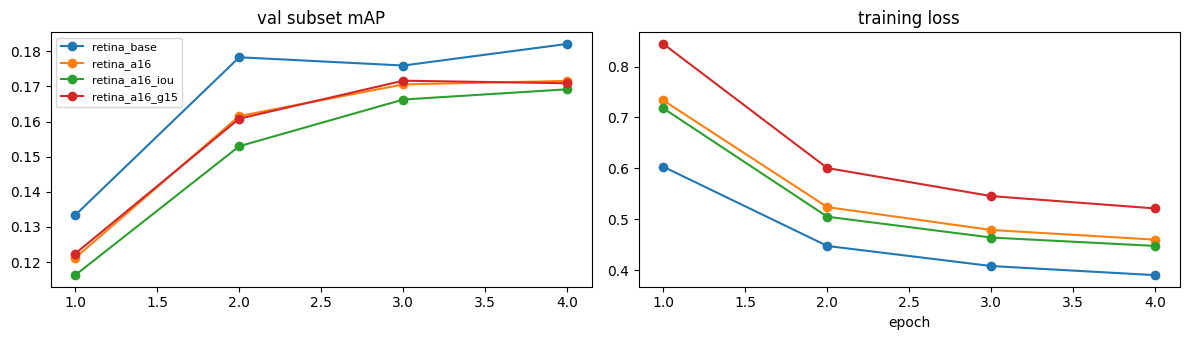

In [11]:
# learning curves on the val subset
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, h in HIST.items():
    if len(h):
        ax[0].plot(h.epoch, h["curve mAP"], marker="o", label=name)
        ax[1].plot(h.epoch, h[[c for c in h if c.startswith("loss")]].sum(1), marker="o", label=name)
ax[0].set_title("val subset mAP"); ax[1].set_title("training loss"); ax[0].legend(fontsize=8); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(WORK / "curves_retina.png", dpi=120); plt.show()

## 5. Comparison with the tuned two-stage detector
Requires the output of notebook 03 (`results_frcnn.csv` / `results_03.csv`) as an input.

In [12]:
prev = find_file("results_03.csv") or find_file("results_frcnn.csv")
if prev is not None:
    F = pd.read_csv(prev, index_col=0)
    best_f = F["mAP"].astype(float).idxmax()
    comp = pd.concat([F.loc[[best_f]], R]).rename(index={best_f: f"{best_f} (tuned two-stage)"})
    display(comp[MAIN].astype(float).round(4))
else:
    print("notebook 03 results not attached: comparison skipped")

notebook 03 results not attached: comparison skipped


## 6. Test submission with the best RetinaNet

In [13]:
BEST = R["mAP"].astype(float).idxmax(); print("best:", BEST)
model = build_model({**BASE, **EXPS[BEST]}); model.load_state_dict(torch.load(find_file(f"retina/{BEST}.pt"), map_location=DEVICE))
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
tp, _ = predict(model, test["path"].tolist())
dets = {i: tp.get(p, np.zeros((0, 6))) for i, p in zip(test["image_id"], test["path"])}
vd.write_submission(dets, ROOT / "test_images.csv", WORK / "submission_retina.csv")
print("written submission_retina.csv")

best: retina_base
written submission_retina.csv
